In [1]:
import pandas as pd
import geopandas as gpd

tiger     = r'C:\Users\sahil\projects\boston-mbta-ridership\data\raw\TIGER'
processed = r'C:\Users\sahil\projects\boston-mbta-ridership\data\processed'

In [2]:
tracts24 = gpd.read_file(tiger + r'\tl_2024_25_tract\tl_2024_25_tract.shp')

print(tracts24.shape)
print(tracts24.columns.tolist())
tracts24[['GEOID', 'NAMELSAD']].head()

(1620, 14)
['STATEFP', 'COUNTYFP', 'TRACTCE', 'GEOID', 'GEOIDFQ', 'NAME', 'NAMELSAD', 'MTFCC', 'FUNCSTAT', 'ALAND', 'AWATER', 'INTPTLAT', 'INTPTLON', 'geometry']


,GEOID,NAMELSAD
0,25017336202,Census Tract 3362.02
1,25017330102,Census Tract 3301.02
2,25017339101,Census Tract 3391.01
3,25017356703,Census Tract 3567.03
4,25017330202,Census Tract 3302.02


In [3]:
acs24 = pd.read_csv(processed + r'\acs_2024_tracts_clean.csv', dtype={'GEOID': str})

# An inner merge keeps only tracts in both, which means only Boston tracts
boston24 = tracts24[['GEOID', 'geometry']].merge(acs24, on='GEOID', how='inner')

print(len(boston24), 'Boston tracts')     # expect 191

191 Boston tracts


In [4]:
tracts19 = gpd.read_file(tiger + r'\tl_2019_25_tract\tl_2019_25_tract.shp')
acs19 = pd.read_csv(processed + r'\acs_2019_tracts_clean.csv', dtype={'GEOID': str})

boston19 = tracts19[['GEOID', 'geometry']].merge(acs19, on='GEOID', how='inner')

print(len(boston19), 'Boston tracts')     # expect 167

167 Boston tracts


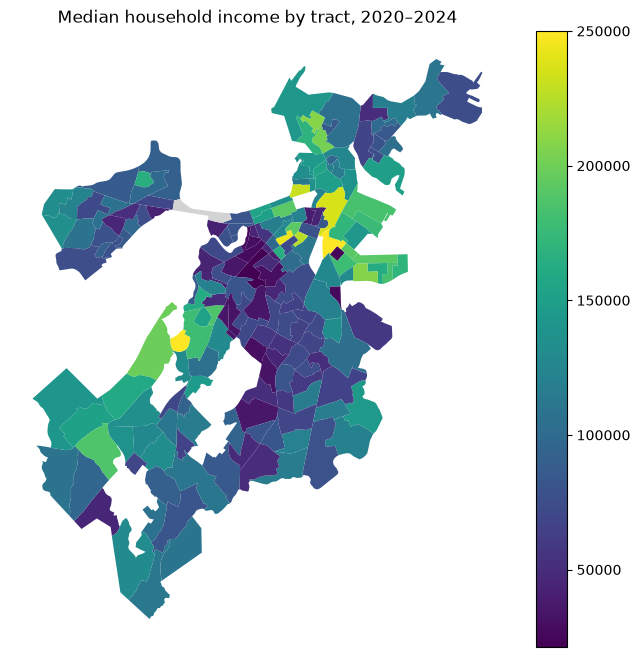

In [5]:
ax = boston24.plot(column='median_hh_income', legend=True, figsize=(8, 8), cmap='viridis',
                   missing_kwds={'color': 'lightgray'})
ax.set_title('Median household income by tract, 2020–2024')
ax.set_axis_off()

In [6]:
boston24.to_file(processed + r'\boston_tracts_2024.geojson', driver='GeoJSON')
boston19.to_file(processed + r'\boston_tracts_2019.geojson', driver='GeoJSON')
print('Saved')

Saved
